# Notbook 002 · Quitar antes de optimizar

**Pregunta:** ¿Hace falta mantener tres proyecciones y una activación no lineal en una neurona multiplicativa, o basta con una operación polinómica pequeña?

**Estado:** experimento comparativo, no una arquitectura novedosa. Se vincula a *Notbook 001 — Operaciones de la neurona*.

## Hipótesis falsables

- **H1:** eliminar la activación SiLU de la neurona interactiva mantiene buena precisión en tareas de fronteras cuadráticas y reduce latencia.
- **H2:** un clasificador cuadrático de 6 parámetros iguala o supera la variante de 28 parámetros en XOR y círculos, con menos bits de parámetros.
- **H3 (límite):** la misma simplificación empeora en tareas que requieren fronteras más complejas, como un anillo o dos lunas.

## Reglas para evitar autoengaño

1. Conjuntos de entrenamiento y prueba separados (mismas muestras para todos los modelos de cada semilla).
2. **10 semillas** para estudiar variabilidad; sin seleccionar hiperparámetros mirando el test.
3. Misma pérdida, optimizador y actualizaciones, aunque **esto no iguala FLOPs ni tiempo total**.
4. Reportamos precisión, pérdida logarítmica, tamaño, tiempo de entrenamiento y latencia. La temporización depende del hardware y de PyTorch eager.
5. Un clasificador cuadrático de 6 parámetros es una técnica conocida. Ganar en XOR/círculos no demostraría una nueva neurona.

**Referencias:**
- MIT 6.390, *Feature Representation*, https://introml.mit.edu/notes/feature_representation.html
- Universidad de Toronto, *Limitations of Linear Models*, https://www.teach.cs.toronto.edu/~csc311notes/linear_classification/limitations_of_linear_models.html
- Liu et al., *Dendritic Integration Inspired Artificial Neural Networks Capture Data Correlation*, NeurIPS 2024, https://proceedings.neurips.cc/paper_files/paper/2024/hash/90b31ad371165eaac2dc6de8993fded7-Abstract-Conference.html

In [1]:
import random, time, statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import make_moons

# Este experimento usa deliberadamente CPU para facilitar ejecución desde Colab gratuito.
torch.set_num_threads(1)
DEVICE = torch.device('cpu')
SEEDS = [11, 23, 37, 41, 53, 67, 71, 83, 97, 101]
N_TRAIN, N_TEST = 1024, 2048
STEPS = 250
LR = 0.03
TAREAS = ['XOR', 'Circulos', 'Lineal', 'Anillo', 'Lunas']
print('torch:', torch.__version__, 'Dispositivo:', DEVICE, 'Semillas:', len(SEEDS))

torch: 2.10.0+cpu Dispositivo: cpu Semillas: 10


## Modelos

- **Lineal (3 parámetros):** sin capa oculta, control mínimo.
- **MLP-1 (5 parámetros):** control con presupuesto pequeño y una neurona oculta SiLU.
- **Aditiva-7 (29 parámetros):** comparación del cuaderno 001.
- **Interactiva-SiLU (28 parámetros):** referencia del cuaderno 001.
- **Interactiva-sin-SiLU (28 parámetros):** ablación de la activación.
- **Cuadrática-6 (6 parámetros):** sin capa oculta; representa todas las funciones cuadráticas de dos variables como logit. Es un **clasificador polinómico conocido**, no una invención.

In [2]:
class Lineal(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(2, 1)
    def forward(self, x):
        return self.fc(x).squeeze(-1)

class MLP(nn.Module):
    def __init__(self, h):
        super().__init__()
        self.entrada = nn.Linear(2, h)
        self.salida = nn.Linear(h, 1)
    def forward(self, x):
        return self.salida(F.silu(self.entrada(x))).squeeze(-1)

class Interactiva(nn.Module):
    def __init__(self, activacion=True):
        super().__init__()
        self.base = nn.Linear(2, 3)
        self.u = nn.Linear(2, 3, bias=False)
        self.v = nn.Linear(2, 3, bias=False)
        self.alpha = nn.Parameter(torch.full((3,), 0.1))
        self.salida = nn.Linear(3, 1)
        self.activacion = activacion
    def forward(self, x):
        z = self.base(x) + self.alpha * self.u(x) * self.v(x)
        return self.salida(F.silu(z) if self.activacion else z).squeeze(-1)

class Cuadratica(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(5, 1)  # 5 monomios + 1 sesgo = 6 parámetros
    def forward(self, x):
        a, b = x[:, 0], x[:, 1]
        phi = torch.stack((a, b, a*a, a*b, b*b), dim=-1)
        return self.fc(phi).squeeze(-1)

MODELOS = {
    'Lineal': Lineal,
    'MLP-1': lambda: MLP(1),
    'Aditiva-7': lambda: MLP(7),
    'Interactiva-SiLU': lambda: Interactiva(True),
    'Interactiva-sin-SiLU': lambda: Interactiva(False),
    'Cuadratica-6': Cuadratica,
}
def parametros(m):
    return sum(p.numel() for p in m.parameters())
conteo = {nombre: parametros(ctor()) for nombre, ctor in MODELOS.items()}
assert conteo == {'Lineal':3, 'MLP-1':5, 'Aditiva-7':29,
                  'Interactiva-SiLU':28, 'Interactiva-sin-SiLU':28,
                  'Cuadratica-6':6}, conteo
print('Parámetros:', conteo)

Parámetros: {'Lineal': 3, 'MLP-1': 5, 'Aditiva-7': 29, 'Interactiva-SiLU': 28, 'Interactiva-sin-SiLU': 28, 'Cuadratica-6': 6}


## Datos

XOR, círculos y lineal reproducen las tres tareas del cuaderno 001. Añadimos **anillo** (dos fronteras radiales) y **lunas** (fronteras curvas). No se ajusta la distribución tras ver resultados. Para la tarea de círculos, un clasificador cuadrático es especialmente adecuado: esto se ha previsto expresamente, no debe ocultarse.

In [3]:
def crear_datos(tarea, n, seed):
    if tarea == 'Lunas':
        puntos, etiquetas = make_moons(n_samples=n, noise=0.10, random_state=seed)
        x = torch.tensor((puntos - [0.5, 0.25]) / 1.5, dtype=torch.float32)
        y = torch.tensor(etiquetas, dtype=torch.float32)
        return x.to(DEVICE), y.to(DEVICE)
    generador = torch.Generator().manual_seed(seed)
    x = torch.rand((n, 2), generator=generador) * 2 - 1
    if tarea == 'XOR':
        y = (x[:, 0] * x[:, 1] > 0).float()
    elif tarea == 'Circulos':
        y = (x.square().sum(dim=1) < 0.75**2).float()
    elif tarea == 'Lineal':
        y = (x[:, 0] + 0.6*x[:, 1] > 0).float()
    elif tarea == 'Anillo':
        radio2 = x.square().sum(dim=1)
        y = ((radio2 > 0.35**2) & (radio2 < 0.80**2)).float()
    else:
        raise ValueError(tarea)
    return x.to(DEVICE), y.to(DEVICE)

@torch.no_grad()
def evaluar(modelo, x, y):
    modelo.eval()
    logits = modelo(x)
    precision = ((logits >= 0).float() == y).float().mean().item()
    perdida = F.binary_cross_entropy_with_logits(logits, y).item()
    return precision, perdida

def entrenar(modelo, x, y):
    modelo.train()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LR)
    t0 = time.perf_counter()
    for _ in range(STEPS):
        optimizador.zero_grad(set_to_none=True)
        perdida = F.binary_cross_entropy_with_logits(modelo(x), y)
        perdida.backward()
        optimizador.step()
    return time.perf_counter() - t0

In [4]:
filas = []
for tarea in TAREAS:
    for seed in SEEDS:
        train_x, train_y = crear_datos(tarea, N_TRAIN, 1000 + seed)
        test_x, test_y = crear_datos(tarea, N_TEST, 2000 + seed)
        for nombre, constructor in MODELOS.items():
            torch.manual_seed(seed)
            np.random.seed(seed)
            random.seed(seed)
            modelo = constructor().to(DEVICE)
            duracion = entrenar(modelo, train_x, train_y)
            acc, bce = evaluar(modelo, test_x, test_y)
            filas.append(dict(tarea=tarea, semilla=seed, modelo=nombre,
                              parametros=parametros(modelo), bits_pesos_fp32=32*parametros(modelo),
                              precision_test=acc, perdida_test=bce,
                              entrenamiento_s=duracion))
    print('Completada:', tarea, '|', len(SEEDS), 'semillas')

resultados = pd.DataFrame(filas)
resultados.to_csv('Notbook_002_resultados.csv', index=False)
resumen = resultados.groupby(['tarea', 'modelo'], as_index=False).agg(
    parametros=('parametros', 'first'),
    precision_media=('precision_test', 'mean'),
    precision_desv=('precision_test', 'std'),
    perdida_media=('perdida_test', 'mean'),
    entrenamiento_s=('entrenamiento_s', 'mean'),
)
print('\nResumen de test (precisión media y desviación entre semillas):')
print(resumen.round(4).to_string(index=False))

Completada: XOR | 10 semillas


Completada: Circulos | 10 semillas


Completada: Lineal | 10 semillas


Completada: Anillo | 10 semillas


Completada: Lunas | 10 semillas

Resumen de test (precisión media y desviación entre semillas):
   tarea               modelo  parametros  precision_media  precision_desv  perdida_media  entrenamiento_s
  Anillo            Aditiva-7          29           0.8510          0.0400         0.3140           0.1102
  Anillo         Cuadratica-6           6           0.7889          0.0208         0.4896           0.0819
  Anillo     Interactiva-SiLU          28           0.8647          0.0415         0.2693           0.1489
  Anillo Interactiva-sin-SiLU          28           0.7979          0.0171         0.4868           0.1432
  Anillo               Lineal           3           0.5891          0.0123         0.6780           0.0683
  Anillo                MLP-1           5           0.6076          0.0126         0.6300           0.0931
Circulos            Aditiva-7          29           0.9878          0.0052         0.0598           0.1185
Circulos         Cuadratica-6           6       

## Velocidad de inferencia (CPU)

Medimos el mismo lote y número de iteraciones con todos los modelos. **No equivale a una comparación de FLOPs ni a un benchmark de Android**, porque el coste de llamadas a PyTorch afecta especialmente a los modelos pequeños. Cada cifra es la mediana de varias repeticiones y depende del equipo.

In [5]:
@torch.no_grad()
def benchmark(modelo, batch=4096, repeticiones=7, iteraciones=100):
    modelo.eval()
    x = torch.randn(batch, 2, device=DEVICE)
    for _ in range(30): modelo(x)
    medidas = []
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        for _ in range(iteraciones): modelo(x)
        medidas.append((time.perf_counter() - t0) * 1000 / iteraciones)
    return statistics.median(medidas)

latencia = pd.DataFrame([{
    'modelo': nombre,
    'parametros': parametros(ctor()),
    'ms_batch_4096': benchmark(ctor())
} for nombre, ctor in MODELOS.items()])
print(latencia.round(4).to_string(index=False))

              modelo  parametros  ms_batch_4096
              Lineal           3         0.0105
               MLP-1           5         0.0199
           Aditiva-7          29         0.1049
    Interactiva-SiLU          28         0.1885
Interactiva-sin-SiLU          28         0.1898
        Cuadratica-6           6         0.0473


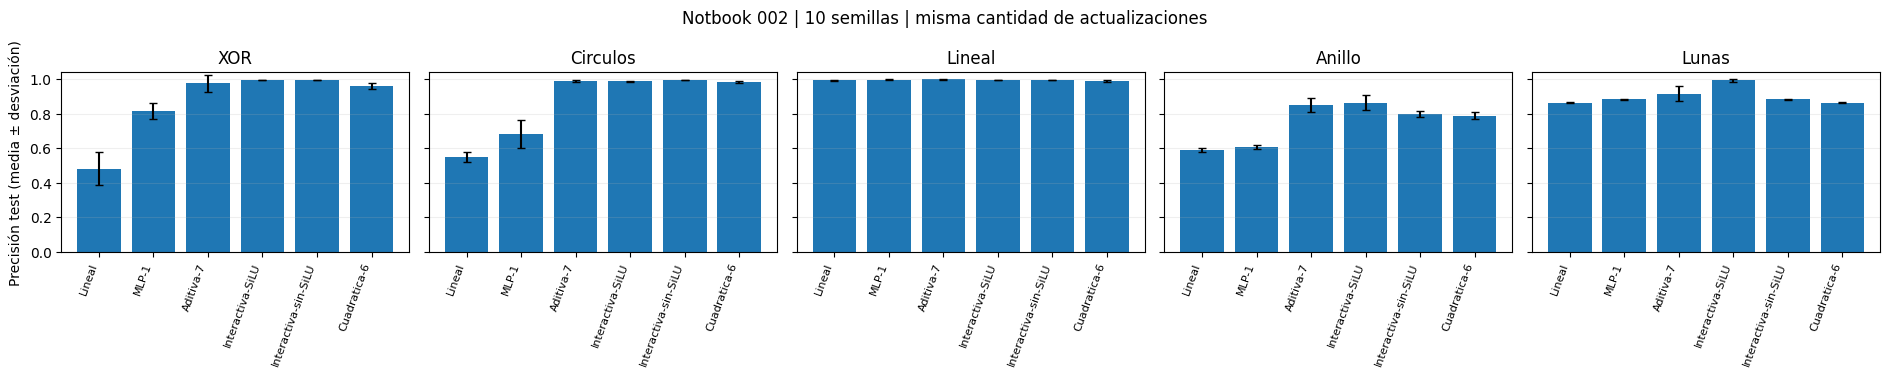

In [6]:
orden = list(MODELOS)
fig, axes = plt.subplots(1, len(TAREAS), figsize=(19, 3.8), sharey=True)
for ax, tarea in zip(axes, TAREAS):
    s = resumen[resumen['tarea'] == tarea].set_index('modelo').loc[orden]
    ax.bar(range(len(s)), s.precision_media, yerr=s.precision_desv, capsize=3)
    ax.set_xticks(range(len(s)), s.index, rotation=70, ha='right', fontsize=8)
    ax.set_title(tarea)
    ax.set_ylim(0, 1.04)
    ax.grid(axis='y', alpha=0.2)
axes[0].set_ylabel('Precisión test (media ± desviación)')
fig.suptitle('Notbook 002 | 10 semillas | misma cantidad de actualizaciones')
plt.tight_layout()
plt.show()

## Interpretación y próximos pasos

1. **No equivocar especialización con superioridad:** el modelo cuadrático puede ganar en XOR/círculos porque sus características están adaptadas a estas tareas.
2. **Ablación estricta:** si *Interactiva-sin-SiLU* no empeora, no necesitábamos SiLU para estas tareas.
3. **Tamaño en bits:** `bits_pesos_fp32` solo mide parámetros FP32; no incluye código ejecutable ni memoria temporal. Es válido para comparar almacenamiento de pesos, no tamaño total desplegado.
4. **Tiempo/energía:** inferencia PyTorch eager no predice necesariamente el rendimiento de una implementación fusionada para móvil.
5. **Generalización:** anillos y lunas prueban parte de las limitaciones. Quedan pendientes ruido más amplio, distribuciones desplazadas y tareas de dimensión alta.
6. **Siguiente experimento si triunfa la simplificación:** representación cuadrática *de bajo rango aprendida*, para evitar los \(O(d^2)\) coeficientes de una matriz cuadrática densa cuando \(d\) crece.

La fórmula general de una cuadrática completa sobre \(d\) entradas necesita \(1+d+d(d+1)/2\) coeficientes. Para \(d=2\), son 6; para \(d=784\), serían 308.505. Por tanto, 6 parámetros **no** implica escalabilidad a imágenes o lenguaje.

**Criterio de descarte:** si una alternativa más simple iguala la calidad y requiere menos memoria y cómputo reales, eliminamos la variante compleja en vez de optimizarla.

## Compilación algebraica exacta: 28 parámetros a 6

**Hallazgo teórico:** la variante **Interactiva-sin-SiLU** calcula siempre una función cuadrática de sus dos entradas. Esto permite **compilar** sus pesos entrenados a los 6 coeficientes de la familia cuadrática sin destilación ni entrenamiento adicional.

Para un modelo con tres unidades ocultas:

\[
z_j=b_j+w_j^\top x+\alpha_j(u_j^\top x)(v_j^\top x),\quad y=c+\sum_j s_jz_j
\]

Se puede expandir como:

\[
y=\beta_0+\beta_1x_1+\beta_2x_2+\beta_3x_1^2+\beta_4x_1x_2+\beta_5x_2^2.
\]

Los coeficientes se calculan sumando contribuciones de los pesos originales; no se guardan los pesos eliminados. **Igualdad matemática exacta**, con pequeñas diferencias de redondeo al evaluar en FP32.

Esto **no demuestra** que una red arbitraria pueda compactarse ni que la representación más pequeña pueda aprender tan fácilmente como la más grande. Es una reparametrización algebraica conocida, demostrada aquí para esta familia particular.

In [7]:
@torch.no_grad()
def compilar_a_cuadratica(origen):
    """Transformación algebraica sin entrenamiento de Interactiva(sin SiLU) a Cuadratica."""
    if origen.activacion:
        raise ValueError('Con SiLU la equivalencia cuadrática deja de cumplirse.')
    destino = Cuadratica().to(device=next(origen.parameters()).device, dtype=next(origen.parameters()).dtype)
    s = origen.salida.weight.detach().reshape(-1)        # (3,)
    b_s = origen.salida.bias.detach().reshape(())         # escalar
    w = origen.base.weight.detach()                      # (3, 2)
    b = origen.base.bias.detach()                        # (3,)
    u = origen.u.weight.detach()                         # (3, 2)
    v = origen.v.weight.detach()                         # (3, 2)
    t = s * origen.alpha.detach()                        # (3,)
    coeficientes = torch.stack([
        torch.sum(s * w[:, 0]),
        torch.sum(s * w[:, 1]),
        torch.sum(t * u[:, 0] * v[:, 0]),
        torch.sum(t * (u[:, 0] * v[:, 1] + u[:, 1] * v[:, 0])),
        torch.sum(t * u[:, 1] * v[:, 1]),
    ])
    constante = b_s + torch.sum(s * b)
    destino.fc.weight.copy_(coeficientes.unsqueeze(0))
    destino.fc.bias.copy_(constante.unsqueeze(0))
    return destino

filas_compilacion=[]
for tarea in TAREAS:
    for seed in SEEDS:
        train_x, train_y = crear_datos(tarea, N_TRAIN, 1000 + seed)
        test_x, test_y = crear_datos(tarea, N_TEST, 2000 + seed)
        torch.manual_seed(seed)
        m = Interactiva(activacion=False).to(DEVICE)
        entrenar(m, train_x, train_y)
        m.eval()
        c = compilar_a_cuadratica(m)
        c.eval()
        with torch.no_grad():
            orig = m(test_x)
            comp = c(test_x)
            error_max = (orig - comp).abs().max().item()
            decisiones_distintas = ((orig >= 0) != (comp >= 0)).sum().item()
        filas_compilacion.append(dict(tarea=tarea, semilla=seed,
                           error_maximo=error_max,
                           predicciones_distintas=int(decisiones_distintas),
                           n_test=len(test_x),
                           accuracy_original=evaluar(m,test_x,test_y)[0],
                           accuracy_compilada=evaluar(c,test_x,test_y)[0]))

compilacion = pd.DataFrame(filas_compilacion)
compilacion.to_csv('Notbook_002_compilacion_exacta.csv', index=False)
print('Parámetros originales:', parametros(m),
      '| compilados:', parametros(c),
      '| reducción:', round(100*(1-parametros(c)/parametros(m)), 2),'%')
print('Error numérico máximo absoluto entre salidas:', format(compilacion.error_maximo.max(),'.8g'))
print('Decisiones distintas en todos los test:', int(compilacion.predicciones_distintas.sum()),
      'de', int(compilacion.n_test.sum()))
print('Latencia de una versión entrenada (ms/lote 4096):',
      'antes=',round(benchmark(m),4), 'después=',round(benchmark(c),4))
print(compilacion.groupby('tarea')[['error_maximo','predicciones_distintas']].agg({'error_maximo':'max','predicciones_distintas':'sum'}).to_string())
assert parametros(m)==28 and parametros(c)==6
# En FP32, evaluaciones algebraicamente equivalentes pueden diferir por redondeo.
assert compilacion.error_maximo.max()<3e-4, 'Diferencias numéricas mayores a lo esperado: revisar conversión.'
# Verificamos adicionalmente en FP64, donde el redondeo es mucho menor.
import copy
m64 = copy.deepcopy(m).double()
c64 = compilar_a_cuadratica(m64)
with torch.no_grad():
    test64 = test_x.double()
    error64 = (m64(test64) - c64(test64)).abs().max().item()
print('Error maximo en FP64 (última tarea y semilla):',format(error64,'.8g'))
assert error64 < 1e-10


Parámetros originales: 28 | compilados: 6 | reducción: 78.57 %
Error numérico máximo absoluto entre salidas: 0.00015258789
Decisiones distintas en todos los test: 0 de 102400
Latencia de una versión entrenada (ms/lote 4096): antes= 0.1732 después= 0.0399
          error_maximo  predicciones_distintas
tarea                                         
Anillo        0.000002                       0
Circulos      0.000031                       0
Lineal        0.000010                       0
Lunas         0.000001                       0
XOR           0.000153                       0
Error maximo en FP64 (última tarea y semilla): 2.6645353e-15


### Qué demuestra esta compilación

- **Sí:** el mismo clasificador cuadrático puede almacenarse con 6 parámetros en vez de los 28 parámetros de la representación factorizada sin SiLU. Esto es exacto como función matemática; en precisión finita hay tolerancia numérica.
- **No:** la variante con SiLU no puede convertirse a una única función cuadrática mediante este método.
- **No:** los parámetros del cuadrático entrenado desde cero y los del cuadrático compilado son equivalentes como *familia funcional*, pero no tienen por qué haber llegado a la misma solución en 250 pasos. La factorización puede afectar al aprendizaje.
- **Advertencia:** esta reducción se obtiene porque hay solo **dos entradas**. Una cuadrática completa puede requerir muchos más parámetros para dimensiones altas. La siguiente investigación debería evaluar factorizaciones de bajo rango y la relación entre facilidad de entrenamiento y simplicidad al desplegar.
